In [87]:
#Install and import libraries

# Install packages if you need them
#%pip install pandas
%pip install seaborn
%pip install scipy

# Import packages
import pandas as pd
import seaborn as sns

# For getting exgaussian function parameters
from scipy.stats import exponnorm
import numpy as np

# For making quantile plots
import matplotlib.pyplot as plt

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [88]:
# load the raw data into a dataframe
# your path will be different
# remember to add /work/ at the beginning of the string
raw = pd.read_csv('/work/Experimental-Psycholinguistics/test2.csv', low_memory =False)

In [89]:
# make a list of all the columns we want to keep
cols = ['Participant Code', 'correctResponse', 'duration', 'response', 'state', 'type', 'Version', 'word']

In [90]:
df = raw[cols] # make a new dataframe with only the columns in cols
df = df[df['type'] != 'practice']  # throw away the practice trials
df = df[df['response'] != 'next']
df = df[df['response'] != 'space']
df = df[df['Participant Code'] != 'MYC5JJYI']
df = df[df['Participant Code'] != 'RBGTZ5J5']

In [91]:
df['correct'] = (df['response'] == df['correctResponse']).astype(int)     # make a new column with 0 or 1 for incorrect / correct
df = df[df['correct'] == 1]                                                # keep only the correct responses 
df = df.rename(columns={'duration': 'rt'})         # rename the soa and duration columns, just to look nicer

In [92]:
dfs = df[df['Version']=='S']    #making a dataframe for the standard version
dfm = df[df['Version']=='M']    #making a dataframe for the mixed version
dfsc = dfs[dfs['type']=='C']    #making a dataframe for the cognates in the standard version
dfmc = dfm[dfm['type']=='C']    #making a dataframe for the cognates in the mixed version
dc = df[df['type']=='C']        #making a dataframe for the cognates in both versions
de = df[df['type']=='E']  
dfse = dfs[dfs['type']=='E']    #making a dataframe for the english in the standard version
dfme = dfm[dfm['type']=='E'] 

In [108]:
dec = df[df['type'] != 'N']
dec = dec[dec['type'] != 'P']
dec = dec[dec['type'] != 'H']
dec = dec[dec['type'] != 'D']

In [94]:
dsec = dfs[dfs['type'] != 'N']
dsec = dsec[dsec['type'] != 'P']
dsec = dsec[dsec['type'] != 'H']
dsec = dsec[dsec['type'] != 'D']

In [95]:
dmec = dfm[dfm['type'] != 'N']
dmec = dmec[dmec['type'] != 'P']
dmec = dmec[dmec['type'] != 'H']
dmec = dmec[dmec['type'] != 'D']

In [96]:
# find average values for the conditions. 
df_grouped = df.groupby(['type', 'state', 'Version'])['rt'].mean().reset_index()
dfsc_grouped = dfsc.groupby(['type', 'state', 'Version'])['rt'].mean().reset_index()
dfmc_grouped = dfmc.groupby(['type', 'state', 'Version'])['rt'].mean().reset_index()
dc_grouped = dc.groupby(['type', 'state', 'Version'])['rt'].mean().reset_index()
de_grouped = de.groupby(['type', 'state', 'Version'])['rt'].mean().reset_index()
dec_grouped = dec.groupby(['type','Version','state'])['rt'].mean().reset_index()
dec_grouped

,type,Version,state,rt
0,C,M,E,659.438565
1,C,S,E,621.523919
2,E,M,E,672.219069
3,E,S,E,656.349733


In [97]:
df_sorted = dec_grouped.sort_values(by=['Version'] , ascending = False)
df_sorted

,type,Version,state,rt
1,C,S,E,621.523919
3,E,S,E,656.349733
0,C,M,E,659.438565
2,E,M,E,672.219069


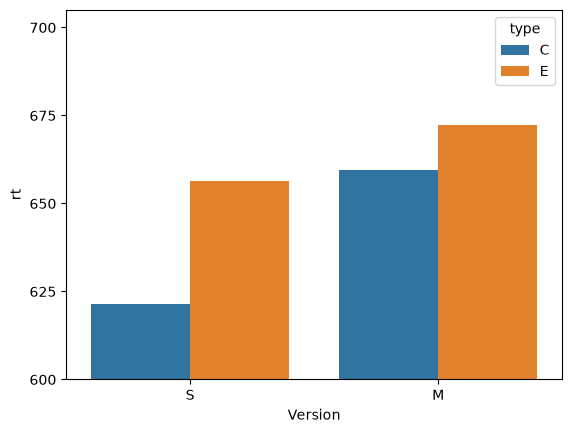

<Figure size 640x480 with 0 Axes>

In [98]:
sns.barplot(data=df_sorted, x='Version', y='rt', hue='type')            # make a barplot for E vs N for each version
plt.ylim(600, 705)  # Set the y-axis limits from 0 to 30
plt.yticks([600, 625, 650, 675, 700])
plt.show()
sns.despine()

In [99]:
acc = pd.read_csv('/work/Experimental-Psycholinguistics/study/accuracy (jank)/acc.csv')
acc = acc.sort_values(by=['Version'] , ascending = False)
acc= acc.sort_values(by=['type'])

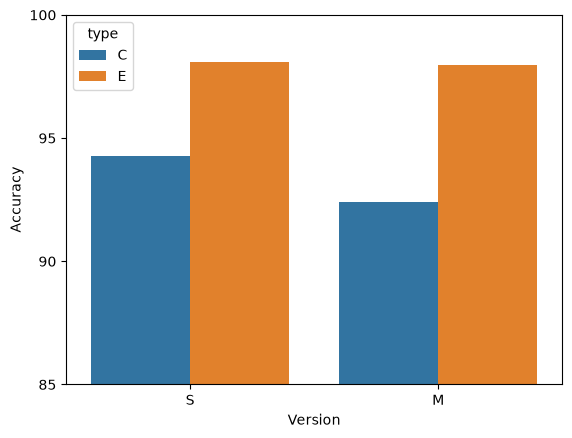

<Figure size 640x480 with 0 Axes>

In [100]:
sns.barplot(data=acc, x='Version', y='Accuracy', hue='type') # make a barplot for E vs N for each version
plt.ylim(85, 100)  # Set the y-axis limits from 0 to 30
plt.yticks([85, 90, 95, 100])
plt.show()
sns.despine()

<Axes: xlabel='rt', ylabel='Participant Code'>

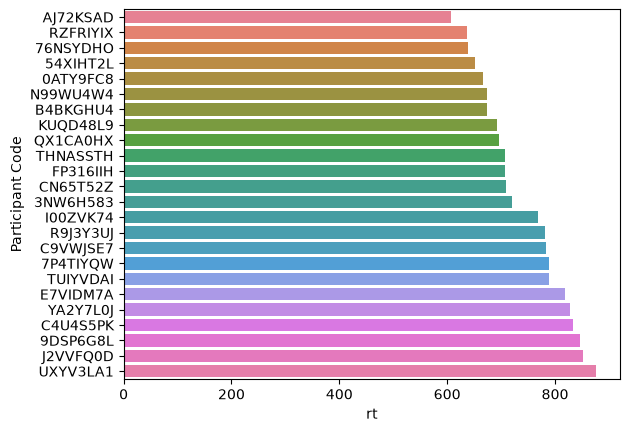

In [101]:
dfp = df.groupby(['Participant Code'])['rt'].mean().reset_index()
dfps = dfp.sort_values(by=['rt'])
sns.barplot(data=dfps, x='rt', y='Participant Code', hue='Participant Code')

<Axes: xlabel='rt', ylabel='Participant Code'>

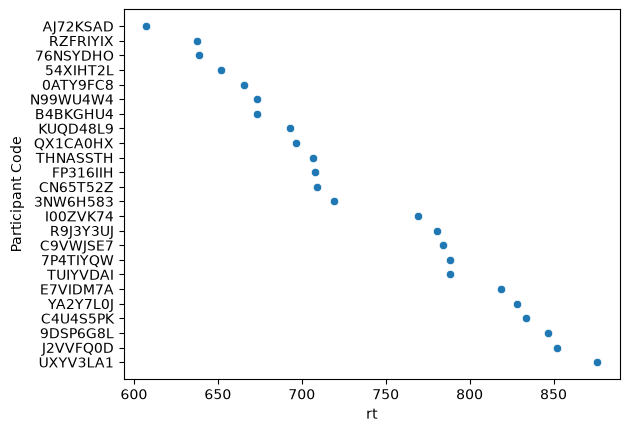

In [102]:
sns.scatterplot(data=dfps, x='rt', y='Participant Code')

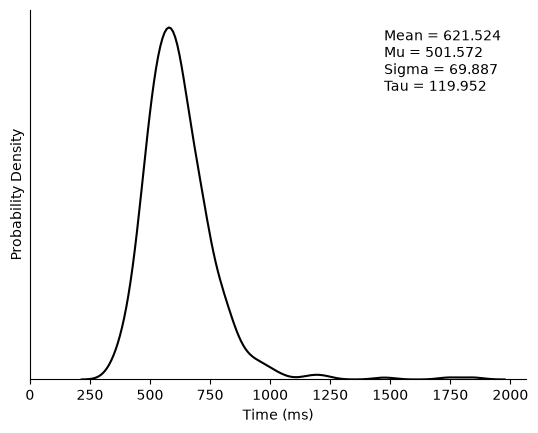

In [103]:
# Plot our response time data like Balota and Yap (2011) do. This is for the standard version

# Fit an ex-gaussian function to the data (maximum liklihood estimation)
K, loc, scale = exponnorm.fit(dfsc['rt'])

# exponorm fits an exgaussian function to the data (here our reaction time data)
# It finds the best values for K, loc, and scale
# K = shape parameter. This is the ratio of the exponential tail to the gaussian spread (K = tau/sigma)
# loc = how much the distribution should shift right or left
# scale = sigma (the standard deviation of the gaussian component of the distribution)

# Recover parameters (give them the same names as in Balota & Yap, 2011)
mu    = loc                            # mu is the same as loc
sigma = scale                          # sigma is the same as scale
tau   = K * scale                      # mean of the exponential component
mean = mu + tau                        # the "theoretical" mean of the fitted function
empmean = dfsc['rt'].mean()             # the "empirical" mean of the data (what "mean" normally, uhh.. means)

# Make a figure like the ones in Balota & Yap (2011). 
ax = sns.kdeplot(data = dfsc, x = 'rt', color = 'black')                                  # plot the data as a distribution
# uncomment the next two lines to check the fit of the function to the data
#x = np.linspace(df['rt'].min(), df['rt'].max(), 200)                                   # datapoint for plotting theoretical exgaussian 
#ax.plot(x, exponnorm.pdf(x, K, loc, scale), color='red', linestyle='--')               # plot theoretical exgauss function on top of acutal data (to check fit)
values = f"Mean = {mean:.3f}\nMu = {mu:.3f}\nSigma = {sigma:.3f}\nTau = {tau:.3f}"      # assemble the text for the legend
ax.text(0.95, 0.95, values,                                                             # x and y coordinates for annotations
        transform=ax.transAxes,                                                         # fixes text box to the figure, not the data
        ha='right', va='top',ma='left',                                                 # position and algin the text in the box
        fontsize=10)                                                                    # I mean, yeah. It's the font size
        #bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))                     # make a box around the annotation, if you want
ax.set(xlabel='Time (ms)', ylabel='Probability Density')                                # Change the axis labels
ax.tick_params(left=False, labelleft=False)                                             # Remove the ticks and values on the y-axis
ax.set_xlim(left=0)                                                                     # Start the x-axis at zero
sns.despine() 

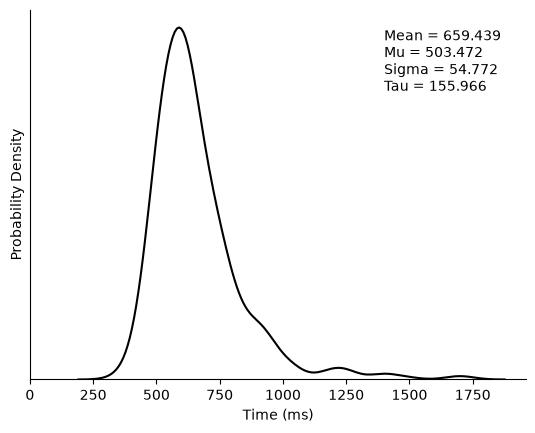

In [104]:
# Plot our response time data like Balota and Yap (2011) do. This is for the mixed version

# Fit an ex-gaussian function to the data (maximum liklihood estimation)
K, loc, scale = exponnorm.fit(dfmc['rt'])

# exponorm fits an exgaussian function to the data (here our reaction time data)
# It finds the best values for K, loc, and scale
# K = shape parameter. This is the ratio of the exponential tail to the gaussian spread (K = tau/sigma)
# loc = how much the distribution should shift right or left
# scale = sigma (the standard deviation of the gaussian component of the distribution)

# Recover parameters (give them the same names as in Balota & Yap, 2011)
mu    = loc                            # mu is the same as loc
sigma = scale                          # sigma is the same as scale
tau   = K * scale                      # mean of the exponential component
mean = mu + tau                        # the "theoretical" mean of the fitted function
empmean = dfmc['rt'].mean()             # the "empirical" mean of the data (what "mean" normally, uhh.. means)

# Make a figure like the ones in Balota & Yap (2011). 
ax = sns.kdeplot(data = dfmc, x = 'rt', color = 'black')                                  # plot the data as a distribution
# uncomment the next two lines to check the fit of the function to the data
#x = np.linspace(df['rt'].min(), df['rt'].max(), 200)                                   # datapoint for plotting theoretical exgaussian 
#ax.plot(x, exponnorm.pdf(x, K, loc, scale), color='red', linestyle='--')               # plot theoretical exgauss function on top of acutal data (to check fit)
values = f"Mean = {mean:.3f}\nMu = {mu:.3f}\nSigma = {sigma:.3f}\nTau = {tau:.3f}"      # assemble the text for the legend
ax.text(0.95, 0.95, values,                                                             # x and y coordinates for annotations
        transform=ax.transAxes,                                                         # fixes text box to the figure, not the data
        ha='right', va='top',ma='left',                                                 # position and algin the text in the box
        fontsize=10)                                                                    # I mean, yeah. It's the font size
        #bbox=dict(boxstyle='round', facecolor='white', alpha=0.7))                     # make a box around the annotation, if you want
ax.set(xlabel='Time (ms)', ylabel='Probability Density')                                # Change the axis labels
ax.tick_params(left=False, labelleft=False)                                             # Remove the ticks and values on the y-axis
ax.set_xlim(left=0)                                                                     # Start the x-axis at zero
sns.despine() 

In [105]:
quantiles = np.arange(.1, 1.0, .1)  # .1 to .9

# per-subject, per-condition quantiles
df_q = (
    df.groupby(['Participant Code', 'Version'])['rt']
      .apply(lambda x: x.quantile(quantiles))
      .rename_axis(['Participant', 'Version', 'quantile'])
      .reset_index(name='rt_q')
)
df_q # inspect the quantiles

,Participant,Version,quantile,rt_q
0,0ATY9FC8,M,0.1,323.45
1,0ATY9FC8,M,0.2,348.50
2,0ATY9FC8,M,0.3,473.45
3,0ATY9FC8,M,0.4,598.40
4,0ATY9FC8,M,0.5,631.85
...,...,...,...,...
427,YA2Y7L0J,S,0.5,712.50
428,YA2Y7L0J,S,0.6,775.00
429,YA2Y7L0J,S,0.7,830.00
430,YA2Y7L0J,S,0.8,931.00


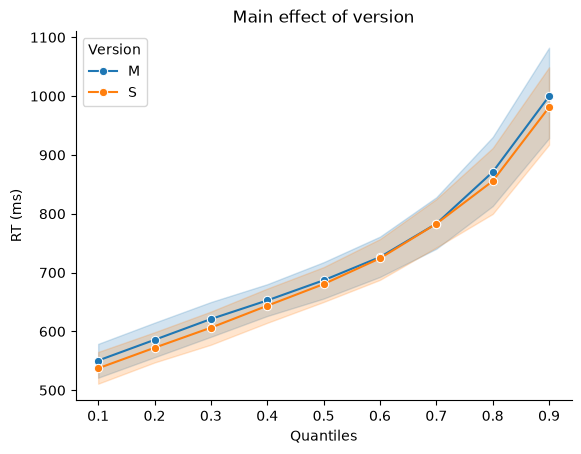

In [106]:

ax = sns.lineplot(data=df_q, x='quantile', y='rt_q', hue='Version', marker='o')
ax.set(xlabel='Quantiles', ylabel='RT (ms)')

ax.set_title('Main effect of version')
ax.set(xlabel='Quantiles', ylabel='RT (ms)')
ax.legend(title='Version')
sns.despine()

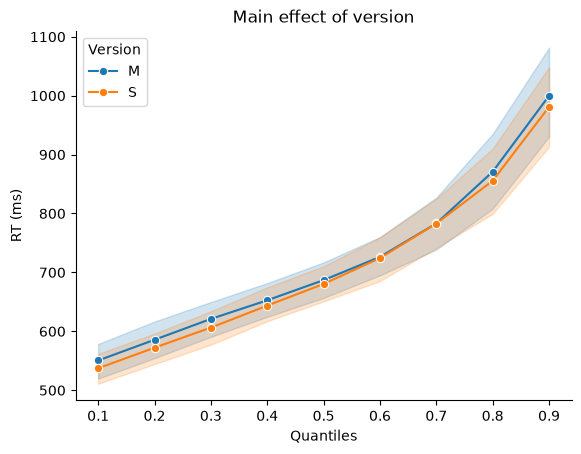

In [107]:
ax = sns.lineplot(data=df_q, x='quantile', y='rt_q', hue='Version', marker='o')
ax.set(xlabel='Quantiles', ylabel='RT (ms)')

ax.set_title('Main effect of version')
ax.set(xlabel='Quantiles', ylabel='RT (ms)')
ax.legend(title='Version')
sns.despine()